In [1]:
import networkx as nx
import random

def barabasi_albert_graph(n, m, seed=None):
    """
    Manually builds a Barabási–Albert (BA) graph using preferential attachment.

    Parameters:
        n (int): Total number of nodes in the final graph.
        m (int): Number of edges each new node attaches to when added.
        seed (int, optional): Random seed for reproducibility.

    Returns:
        G (nx.Graph): The generated BA graph.
    """
    if seed is not None:
        random.seed(seed)

    if m < 1 or m >= n:
        raise ValueError("m must satisfy 1 <= m < n")

    # Initialize with a small fully connected (complete) graph of m nodes
    G = nx.Graph()
    G.add_nodes_from(range(m))
    for i in range(m):
        for j in range(i + 1, m):
            G.add_edge(i, j)

    # A list of nodes where each node appears as many times as its degree.
    # This is used for preferential attachment sampling.
    node_list = list(G.nodes()) * (m - 1)
    for new_node in range(m, n):
        # Select m distinct existing nodes with probability proportional to degree
        targets = set()
        while len(targets) < m:
            chosen = random.choice(node_list)
            targets.add(chosen)

        # Add the new node and edges to selected targets
        G.add_node(new_node)
        for t in targets:
            G.add_edge(new_node, t)

        # Update node_list for degree weighting
        node_list.extend(targets)
        node_list.extend([new_node] * m)

    return G

In [2]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend, weighted=False):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    # G.add_nodes_from(list(range(backend.num_qubits)))
    if weighted:
        # props = backend.properties()
        # # Extract two-qubit gate errors
        # for gate in props.gates:
        #     if gate.gate in ['cz', 'cx', 'ecr']:
        #         q1, q2 = gate.qubits
        #         err = next(param.value for param in gate.parameters if param.name == "gate_error")
        #         if err<1.0:
        #             G.add_edge(q1, q2, weight=1-err)

        props = backend.properties()
        conf = backend.configuration()
        coupling = conf.coupling_map

        alpha=0.75
        beta_readout=0.7
        beta_t12=0.2
        beta_gate=0.1

        G = nx.Graph()
        # G.add_nodes_from(range(conf.num_qubits))

        # ---- Node (1Q) noise ----
        node_noise = {}
        for q in range(conf.num_qubits):
            qb = props.qubits[q]
            for p in qb:
                if p.name=='T1':
                    if p.value>0:
                        t1 = p.value
                    else:
                        t1 = 100e6
                if p.name=='T2':
                    if p.value>0:
                        t2 = p.value
                    else:
                        t2 = 100e6
                if p.name=='readout_error':
                    readout_err = p.value
            decoh = (1 / t1 + 1 / t2) if t1 > 0 and t2 > 0 else 0
            gate_errs = [
                param.value
                for g in props.gates
                if len(g.qubits) == 1 and g.qubits[0] == q
                for param in g.parameters
                if param.name == "gate_error"
            ]
            # print(gate_errs)
            max_gate_err = np.mean(gate_errs) if gate_errs else 0
            node_noise[q] = (
                beta_readout * readout_err
                + beta_t12 * decoh
                + beta_gate * max_gate_err
            )
            # print(q, node_noise[q])
            G.add_node(q, weight=max(1 - node_noise[q], 0))
            # print(q, decoh, max_gate_err, readout_err, 1-node_noise[q])

        # ---- Edge (2Q) noise ----
        for g in props.gates:
            if len(g.qubits) == 2:
                q1, q2 = g.qubits
                err = next(param.value for param in g.parameters if param.name == "gate_error")
                node_term = (node_noise[q1] + node_noise[q2]) / 2
                # print(node_term)
                combined_noise = alpha * err + (1 - alpha) * node_term
                reliability = 1 - combined_noise
                # if reliability>0.9:
                G.add_edge(q1, q2, weight=max(reliability, 0))
    else:
        G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    
import matplotlib.pyplot as plt
def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()


def selective_bfs(G, source, n, weight='weight', threshold=0.9, relax_factor=0.5, min_threshold=0.0):
    if source not in G:
        raise ValueError(f"Source node {source} not in graph")

    visited = set([source])
    q = deque([source])
    sub_nodes = [source]
    current_threshold = threshold

    while len(sub_nodes) < n:
        progress = False
        temp_q = deque(q)

        while temp_q and len(sub_nodes) < n:
            u = temp_q.popleft()
            for v in G.neighbors(u):
                if v not in visited:
                    w = G[u][v].get(weight, 1.0)
                    if w >= current_threshold:
                        visited.add(v)
                        q.append(v)
                        sub_nodes.append(v)
                        progress = True
                        if len(sub_nodes) >= n:
                            break

        # If no new nodes were added, relax the threshold
        if not progress:
            current_threshold *= relax_factor
            if current_threshold < min_threshold:
                # As a last resort, include any remaining nodes
                remaining = [v for v in G.nodes if v not in visited]
                sub_nodes.extend(remaining[: n - len(sub_nodes)])
                break

    return G.subgraph(sub_nodes).copy()

import networkx as nx
import numpy as np

def extract_low_noise_subgraph(
    backend,
    n_target,
    beta_readout=0.75,
    beta_t12=0.2,
    beta_gate=0.1,
    start_percentile=0.90,
    relax_step=0.05,
    min_percentile=0.01,
):
    """
    Extract a low-noise connected subgraph using statistical filtering.
    
    Nodes/edges are selected by percentile thresholds rather than fixed values.
    """
    if n_target > backend.configuration().num_qubits:
        return get_coupling_graph(backend)
    # if n_target < backend.configuration().num_qubits // 5:
    #     n_target*=2
    props = backend.properties()
    conf = backend.configuration()

    G = nx.Graph()

    # ---- Compute node reliability ----
    for q in range(conf.num_qubits):
        qb = props.qubits[q]
        readout_err = qb[2].value
        t1 = qb[0].value if qb[0].value > 0 else np.inf
        t2 = qb[1].value if qb[1].value > 0 else np.inf
        decoherence_term = (1.0 / t1 + 1.0 / t2)

        gate_errs = [
            param.value
            for g in props.gates if len(g.qubits) == 1 and g.qubits[0] == q
            for param in g.parameters if param.name == "gate_error"
        ]
        avg_gate_err = np.mean(gate_errs) if gate_errs else 0.0

        node_noise = (
            beta_readout * readout_err +
            beta_t12 * decoherence_term +
            beta_gate * avg_gate_err
        )
        # print(readout_err, decoherence_term, avg_gate_err)

        reliability = max(1 - node_noise, 0)
        G.add_node(q, reliability=reliability)

    # ---- Compute edge reliability ----
    for g in props.gates:
        if len(g.qubits) == 2:
            q1, q2 = g.qubits
            err_2q = next(param.value for param in g.parameters if param.name == "gate_error")
            reliability = max(1 - err_2q, 0)
            G.add_edge(q1, q2, reliability=reliability)

    # ---- Iterative percentile relaxation ----
    percentile = start_percentile

    # Compute statistical thresholds
    node_vals = np.array([d["reliability"] for _, d in G.nodes(data=True)])
    edge_vals = np.array([d["reliability"] for _, _, d in G.edges(data=True)])
    while percentile >= min_percentile:
        node_thresh = np.quantile(node_vals, percentile)
        edge_thresh = np.quantile(edge_vals, percentile)
        # print(percentile, len([x for x in edge_vals if x>edge_thresh])/len(edge_vals))

        # Filter nodes
        good_nodes = [q for q in G.nodes if G.nodes[q]["reliability"] >= node_thresh]
        G1 = G.subgraph(good_nodes).copy()

        # Filter edges
        good_edges = [(u, v) for u, v in G1.edges
                      if G1[u][v]["reliability"] >= edge_thresh]

        G2 = nx.Graph()
        G2.add_nodes_from(G1.nodes(data=True))
        G2.add_edges_from([(u, v, G1[u][v]) for u, v in good_edges])
        # draw_graph_custom(G2)

        # Connected components
        components = list(nx.connected_components(G2))

        # Score each component: (-size, diameter)
        # Negative size because we want larger size first
        def comp_score(comp):
            Hc = G2.subgraph(comp)
            # Compute diameter only once per component
            try:
                diameter = nx.diameter(Hc)
            except nx.NetworkXError:
                # Graph must be connected but just in case
                diameter = float('inf')
            return (-len(comp), diameter)

        # Sort by:
        # 1) descending size
        # 2) ascending diameter
        components_sorted = sorted(components, key=comp_score)

        # Pick the first that meets the target size
        for comp in components_sorted:
            if len(comp) >= n_target:
                return G2.subgraph(comp).copy()

        # Relax if no valid component
        percentile -= relax_step

    return get_coupling_graph(backend)

def central_node(G):
    # Compute eccentricity of each node
    ecc = nx.eccentricity(G)
    
    # Find center nodes (min eccentricity)
    min_ecc = min(ecc.values())
    center_nodes = [n for n, e in ecc.items() if e == min_ecc]
    
    # If multiple centers exist, break ties using closeness centrality
    if len(center_nodes) > 1:
        closeness = nx.closeness_centrality(G)
        center_nodes.sort(key=lambda n: closeness[n], reverse=True)
    
    return center_nodes[0]  # Best root

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None, noise_aware=False, na_method='selective_bfs'):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            if noise_aware:
                if na_method=='selective_bfs':
                    G = get_coupling_graph(backend, weighted=True)
                else:
                    G = extract_low_noise_subgraph(backend, n_target=int(1.5*num_nodes))
            else:
                G = get_coupling_graph(backend)
            if not root_on_backend:
                root_on_backend = central_node(G)
            
            if noise_aware and na_method=='selective_bfs':
                tree_layout = selective_bfs(G, source=root_on_backend, n=num_nodes)
            else:
                tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)

            order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

def optimize_routed_circuit(routed_circuit, backend, opt_level=3):
    """
    Optimize a circuit that has already been routed (no more SWAPs needed).
    Ensures layout and routing passes are disabled.
    """

    optimized = transpile(
        routed_circuit,
        backend=backend,
        optimization_level=opt_level,
        basis_gates=backend.basis_gates,
        coupling_map=backend.coupling_map,
        seed_transpiler=0,
        layout_method=None,   # prevents modifying qubit assignments
        routing_method=None,  # prevents adding more SWAPs
    )
    
    return optimized



In [3]:
def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [4]:
def show_layout_on_backend(inp, backend, title=None, node_size=150):
    if isinstance(inp, QuantumCircuit):
        transpiled = inp

        # Extract assigned physical qubits
        assigned_phys = list(transpiled.layout.final_virtual_layout(filter_ancillas=True).get_physical_bits().keys())
    else:
        assigned_phys = list(inp.nodes())

    # Get the coupling map as a NetworkX graph
    coupling_map = backend.configuration().coupling_map
    G = nx.Graph()
    G.add_edges_from(coupling_map)

    draw_graph_custom(G, highlight_nodes=assigned_phys, title=title, node_size=node_size)

In [5]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping


In [6]:
def normalized_graph(graph:nx.Graph):
    for u,v in list(graph.edges):
        graph[u][v]['weight'] = 1.0/np.sqrt(graph.degree(u)*graph.degree(v))
    return graph

In [7]:
def return_ops(backend, 
               graph_type='reg', 
               param=4, 
               average_over=5, 
               node_list=list(range(10,101,2)), 
               reps=2, 
               tech='1D', 
               k=2, 
               topology='tree_dfs', 
               opt_level=3, 
               op_name='ecr', 
               use_custom=True, 
               stop_after_routing=False, 
               normalize_laplacian=False, 
               noise_aware=False, 
               na_method='selective_bfs'):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)
        gen = gen_QAOA_circuit(graph, reps=reps)
        spec_graph=graph
        if tech=='1D':
            tree = dfs_spanning_tree(graph, root=0)
            
            proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology, noise_aware=noise_aware, na_method=na_method)
        elif tech=='2D':
            logical_embedding = graph_laplacian_embedding(spec_graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]

            H = get_coupling_graph(backend, weighted=noise_aware)
            if noise_aware:
                S = selective_bfs(H, source=H.number_of_nodes()//2, n=n)
            else:
                S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(graph, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=proposed_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

In [9]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeBrisbane()
# backend = FakeTorino()
# backend = FakeFez()

In [10]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
backend = FakeBrisbane()

In [196]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', k=5, use_custom=True, opt_level=3, stop_after_routing=True, reps=1, noise_aware=True, normalize_laplacian=True, na_method='pruning_bfs')

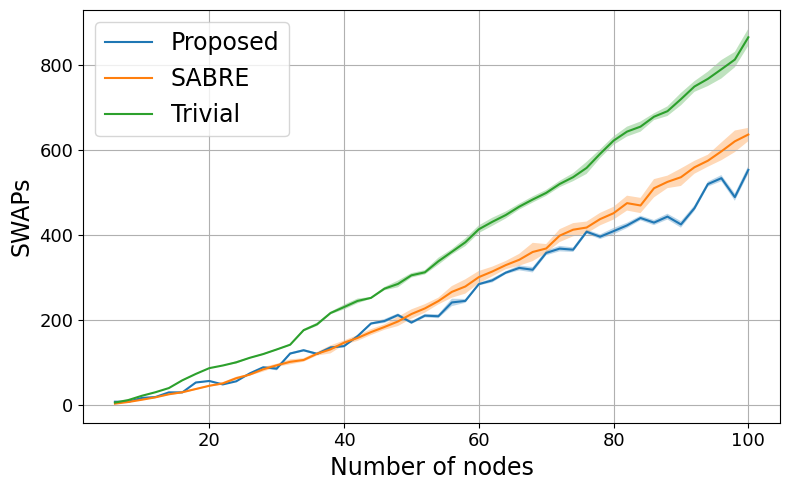

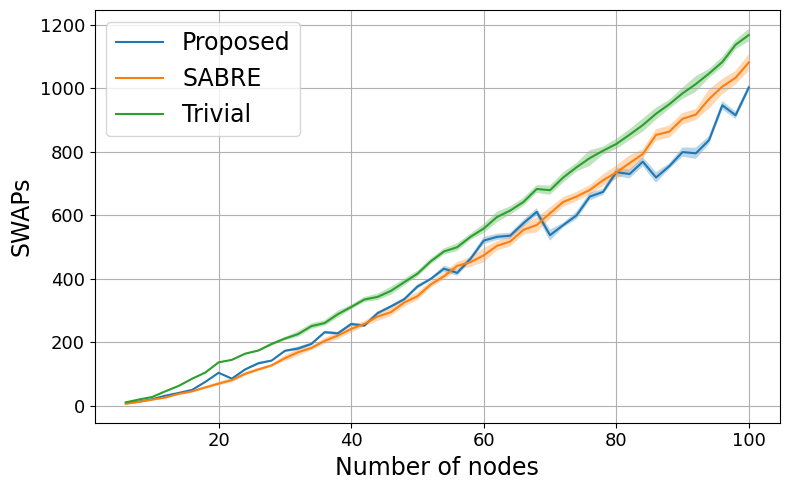

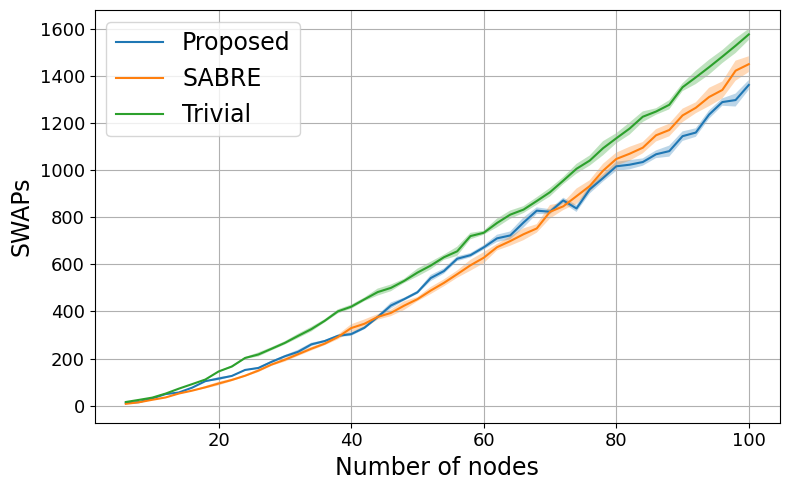

In [198]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [203]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', k=5, use_custom=True, opt_level=3, stop_after_routing=True, reps=1, noise_aware=True, normalize_laplacian=True, na_method='selective_bfs')

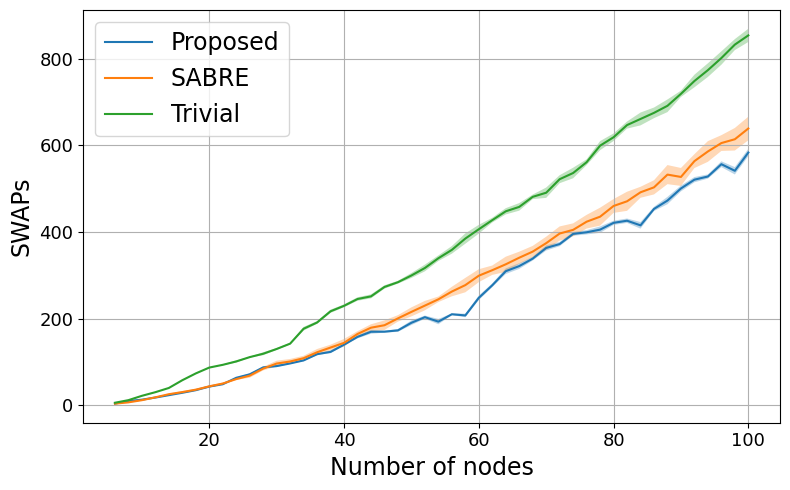

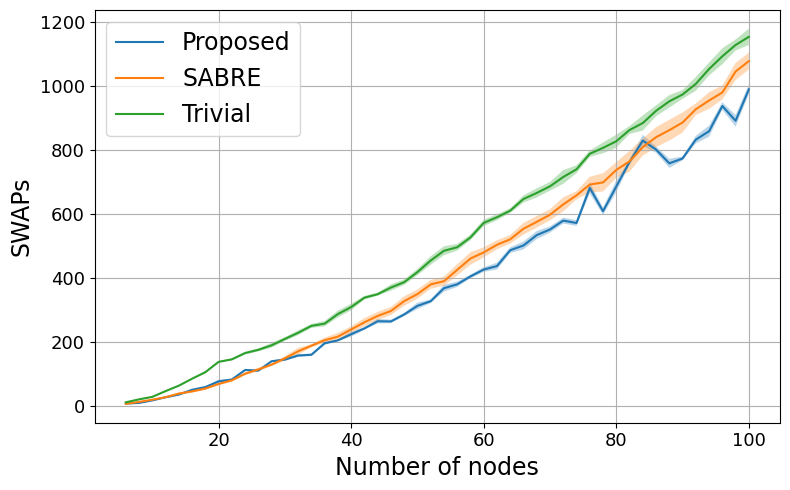

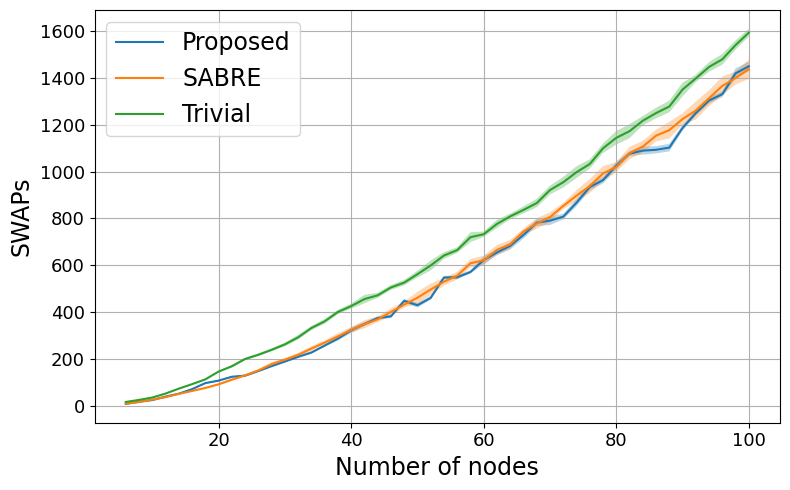

In [204]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [173]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=10, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', k=5, use_custom=True, opt_level=3, stop_after_routing=True, reps=1, noise_aware=False, normalize_laplacian=True)

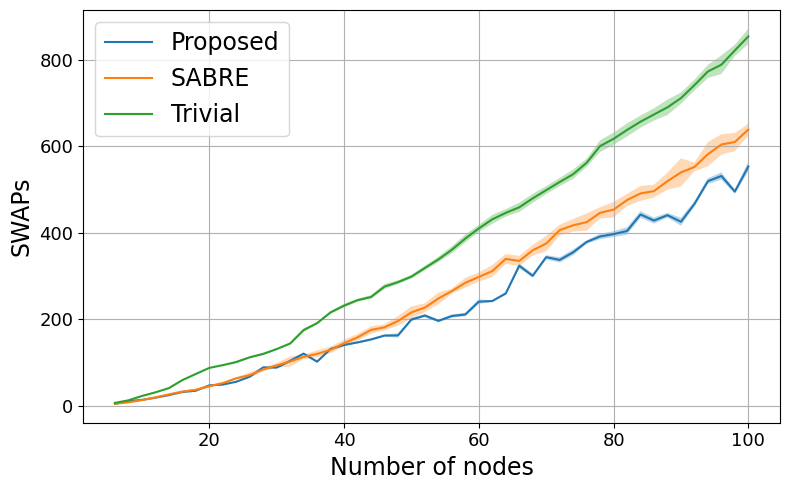

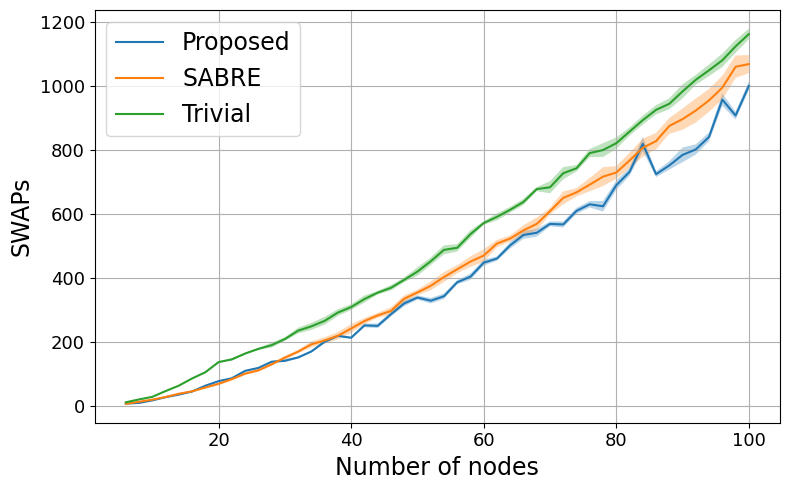

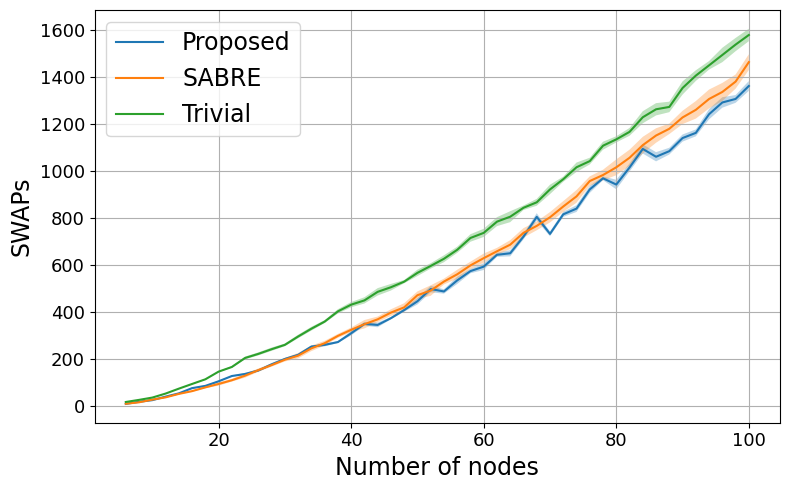

In [174]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


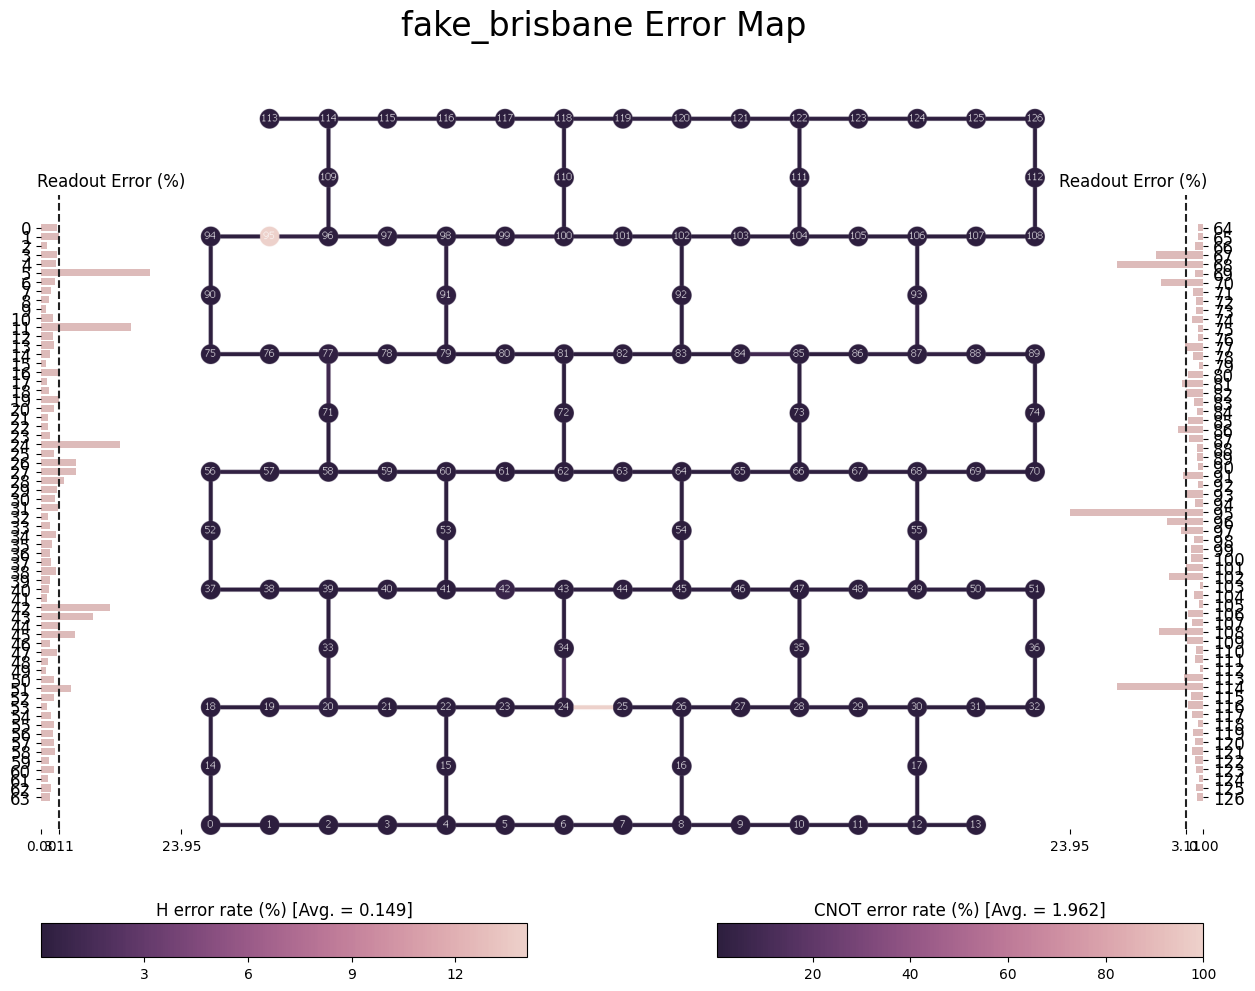

In [22]:
from qiskit.visualization import plot_error_map, plot_gate_map

plot_error_map(FakeBrisbane())

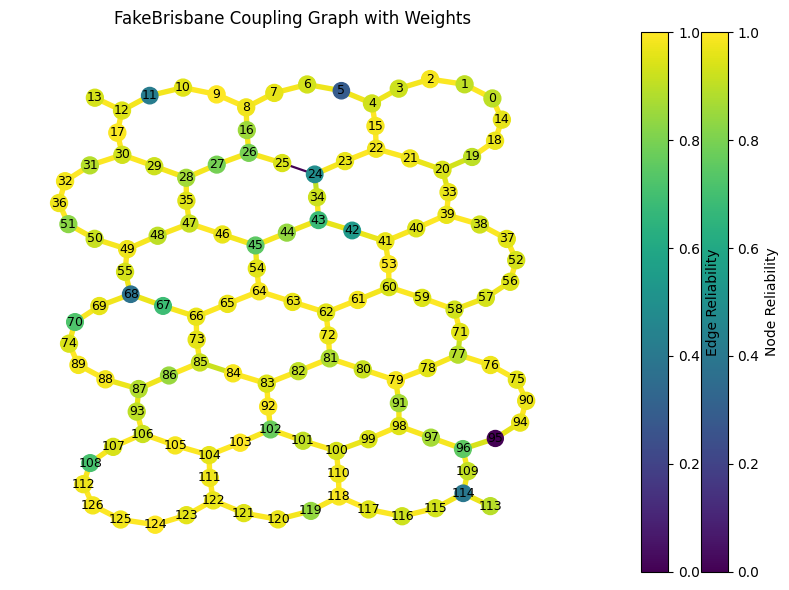

In [11]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def draw_weighted_graph(
    G,
    backend,
    node_weight_key=None,
    edge_weight_key='weight',
    with_labels=True,
    node_size_base=100,
    edge_width_base=3.0,
    cmap='viridis',
    layout='kamada_kawai',
    figsize=(8, 6),
    title=None,
):
    import matplotlib.pyplot as plt
    import numpy as np
    import networkx as nx

    # ---- Layout ----
    graph = get_coupling_graph(backend)
    if layout == 'spring':
        pos = nx.spring_layout(G, seed=0)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(graph)
    elif layout == 'spectral':
        pos = nx.spectral_layout(G)
    else:
        raise ValueError("Unknown layout")

    # ---- Edge weights ----
    edge_weights = np.array([
        G[u][v].get(edge_weight_key, 1.0)
        for u, v in G.edges
    ])
    edge_weights = np.clip(edge_weights, 0.0, 1.0)

    edge_colors = edge_weights
    edge_widths = edge_width_base * (0.3 + edge_weights)

    # ---- Node weights ----
    if node_weight_key is not None:
        node_weights = np.array([
            G.nodes[n].get(node_weight_key, 1.0)
            for n in G.nodes
        ])
        node_weights = np.clip(node_weights, 0.0, 1.0)
        node_colors = node_weights
        node_sizes = node_size_base * (0.5 + node_weights)
    else:
        node_weights = None
        node_colors = 'lightblue'
        node_sizes = node_size_base

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=figsize)

    nodes = nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=node_sizes,
        cmap=cmap,
        ax=ax
    )

    edges = nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        width=edge_widths,
        edge_cmap=plt.get_cmap(cmap),
        ax=ax
    )

    if with_labels:
        nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)

    # ---- Node colorbar ----
    if node_weights is not None:
        sm_nodes = plt.cm.ScalarMappable(
            cmap=cmap,
            norm=plt.Normalize(vmin=0, vmax=1)
        )
        sm_nodes.set_array([])
        cbar_nodes = plt.colorbar(
            sm_nodes, ax=ax, fraction=0.046, pad=0.04
        )
        cbar_nodes.set_label("Node Reliability")

    # ---- Edge colorbar ----
    sm_edges = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=plt.Normalize(vmin=0, vmax=1)
    )
    sm_edges.set_array([])
    cbar_edges = plt.colorbar(
        sm_edges, ax=ax, fraction=0.046, pad=0.10
    )
    cbar_edges.set_label("Edge Reliability")

    if title:
        ax.set_title(title)

    ax.axis('off')
    plt.tight_layout()
    plt.show()



backend = FakeBrisbane()
# backend = FakeFez()
graph = get_coupling_graph(backend, weighted=True)
draw_weighted_graph(graph, backend, node_weight_key='weight', title="FakeBrisbane Coupling Graph with Weights")

In [18]:
graph[96]

AtlasView({109: {'weight': np.float64(0.9848794181288999)}, 97: {'weight': np.float64(0.9834687836611443)}, 95: {'weight': np.float64(0.9482392626656202)}})

In [9]:
FakeBrisbane().properties().qubits[0][4].name

'readout_error'

In [16]:
get_coupling_graph(FakeBrisbane(), weighted=True).edges(data=True)

EdgeDataView([(0, 1, {'weight': np.float64(0.9884004311280223)}), (0, 14, {'weight': np.float64(0.988862912061162)}), (1, 2, {'weight': np.float64(0.9905621720241193)}), (2, 3, {'weight': np.float64(0.9822988505657637)}), (3, 4, {'weight': np.float64(0.974503036050176)}), (4, 15, {'weight': np.float64(0.9914935943150728)}), (4, 5, {'weight': np.float64(0.9768630765082784)}), (5, 6, {'weight': np.float64(0.9738748980727335)}), (6, 7, {'weight': np.float64(0.9839718251365603)}), (7, 8, {'weight': np.float64(0.9860961033606562)}), (8, 9, {'weight': np.float64(0.9915494990489282)}), (8, 16, {'weight': np.float64(0.9835943436313739)}), (9, 10, {'weight': np.float64(0.9933698353281646)}), (10, 11, {'weight': np.float64(0.9799383037605648)}), (11, 12, {'weight': np.float64(0.9813051719253817)}), (12, 13, {'weight': np.float64(0.9905779524098941)}), (12, 17, {'weight': np.float64(0.9942628738922232)}), (14, 18, {'weight': np.float64(0.9913623119453521)}), (15, 22, {'weight': np.float64(0.99331

In [217]:
root = max(graph.nodes, key=lambda q: graph.nodes[q]["weight"])
root

KeyError: 'weight'

In [85]:
Fake().configuration().basis_gates


['cz', 'id', 'rz', 'sx', 'x']

In [98]:
# props = FakeFez().properties()
props = FakeBrisbane().properties()
for gate in props.gates:
    if len(gate.qubits) == 1 and gate.qubits[0] == 113:
        names = [p.name for p in gate.parameters]
        if "gate_error" in names:
            err = [p.value for p in gate.parameters if p.name == "gate_error"][0]
            print(gate.gate, err)



id 0.00028195151136613776
rz 0
sx 0.00028195151136613776
x 0.00028195151136613776


In [99]:
q = 113  # example qubit index

qb = props.qubits[q]

T1 = qb[0].value
T2 = qb[1].value
readout_error = qb[2].value

print(f"Qubit {q}")
print(f"  T1 = {T1:.2e}")
print(f"  T2 = {T2:.2e}")
print(f"  Readout error = {readout_error:.4f}")


Qubit 113
  T1 = 2.58e+02
  T2 = 2.37e+02
  Readout error = 5.0320


In [92]:
edge_errors = {}
q1=24
q2=25

for gate in props.gates:
    if len(gate.qubits) == 2 and set(gate.qubits) == {q1, q2}:
        err = next(p.value for p in gate.parameters if p.name == "gate_error")
        edge_errors[gate.gate] = err

print(f"2Q gate errors between {q1}-{q2}:")
for g, e in edge_errors.items():
    print(f"  {g}: {e:.4e}")


2Q gate errors between 24-25:
  ecr: 1.0000e+00


In [107]:
graph = get_coupling_graph(FakeFez(), weighted=True)

0 0.0440854568356652 0.0007640689403641555 0.011474609375 0.9830742751763305
1 0.007213363360344251 0.00017830158250577147 0.01171875 0.9903363721696806
2 0.013645919301352944 0.00019759080931036193 0.0048828125 0.9938330883087984
3 0.009190671784747917 0.00023918657563726055 0.015869140625 0.9870295485479867
4 0.011413852346358267 0.000212360695609903 0.00146484375 0.9966706028361674
5 0.010055230138389146 0.00027829661417029506 0.007568359375 0.9926632727484052
6 0.012407678730950247 0.00025243453092972103 0.0068359375 0.992708064550717
7 0.027951683645160742 0.00029902880228578567 0.02099609375 0.9796824947657393
8 0.03647480373350704 0.0002755213798244802 0.004150390625 0.9897722136778161
9 0.022609340194299415 0.0002377305089616369 0.007080078125 0.990498304222744
10 0.014427229713481106 0.0002414606338335861 0.003173828125 0.9948687283064204
11 0.02321742316112327 0.00019574237225861136 0.01025390625 0.9881592067555495
12 0.02545548918121764 0.000258654056224904 0.023681640625 0.

In [12]:
# backend=FakeBrisbane()
backend=FakeBrisbane()

62 9


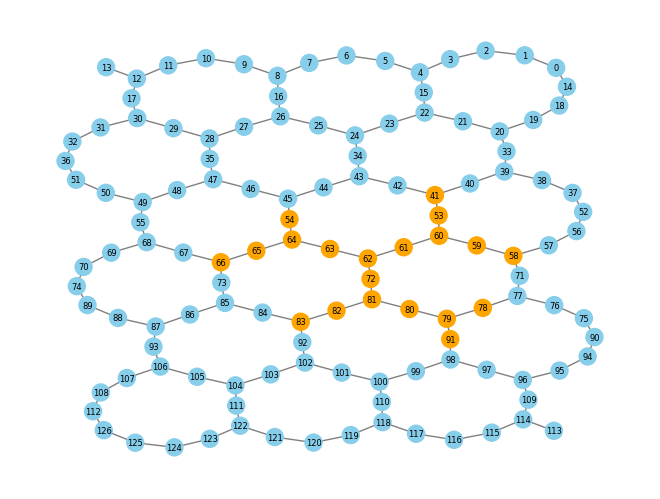

In [130]:
n=20
H = get_coupling_graph(backend, weighted=True)
S = selective_bfs(H, source=central_node(H), n=n)
print(central_node(S), nx.diameter(S))
show_layout_on_backend(S, backend)

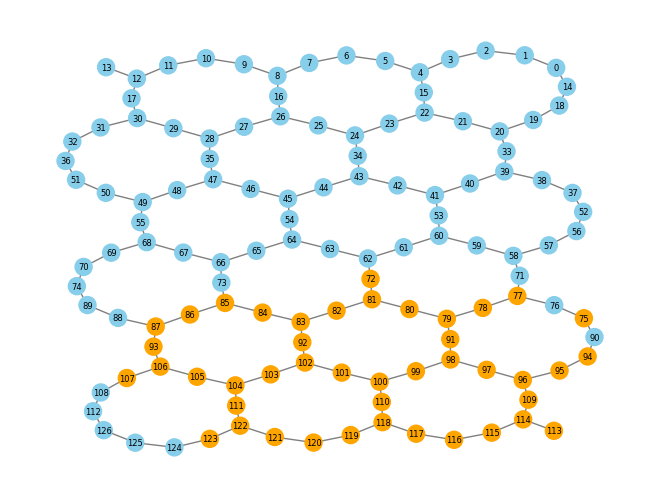

In [208]:
graph = nx.random_regular_graph(n=44, d=5, seed=0)
gen = gen_QAOA_circuit(graph, reps=2)
opt = final_optimized_circuit(gen, backend, opt_level=3)
show_layout_on_backend(opt, backend)

In [236]:
H = get_coupling_graph(FakeBrisbane(), weighted=True)
[u for u in H.nodes if H.degree(u) >= 3]

[4,
 8,
 12,
 20,
 22,
 24,
 26,
 28,
 30,
 39,
 41,
 43,
 45,
 47,
 49,
 58,
 60,
 62,
 64,
 66,
 68,
 77,
 79,
 81,
 83,
 85,
 87,
 96,
 98,
 100,
 102,
 104,
 106,
 114,
 118,
 122]

23 22


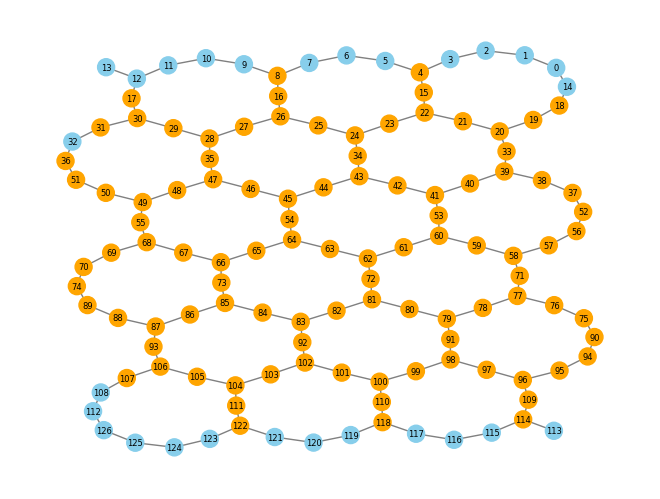

In [24]:
backend=FakeBrisbane()
H = get_coupling_graph(backend)
S = build_tree_cluster(H, source=backend.num_qubits//2, n=100)
print(root, nx.diameter(S))
show_layout_on_backend(S, backend)

118 23


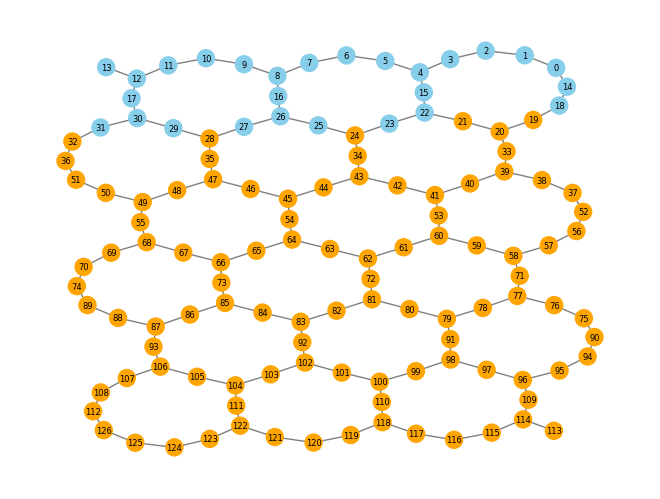

In [25]:
backend=FakeBrisbane()
H = get_coupling_graph(backend, weighted=True)
high_degree_nodes = [u for u in H.nodes if H.degree(u) >= 3]
root = max(high_degree_nodes, key=lambda q: H.nodes[q]["weight"])
S = selective_bfs(H, source=root, n=100)
print(root, nx.diameter(S))
show_layout_on_backend(S, backend)

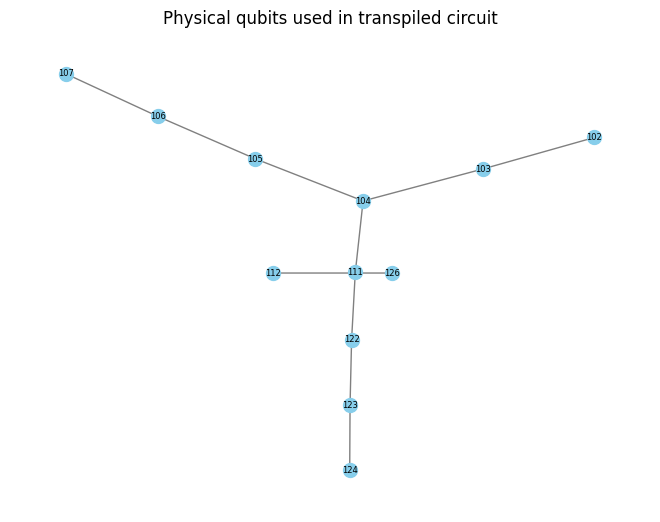

In [177]:
n=12
graph = nx.random_regular_graph(n=n, d=3, seed=0)
gen = gen_QAOA_circuit(graph, reps=1)
transpiled = final_optimized_circuit(gen, backend, opt_level=3)
assigned_phys = list(transpiled.layout.final_virtual_layout(filter_ancillas=True).get_physical_bits().keys())
G = get_coupling_graph(backend).subgraph(assigned_phys).copy()
draw_graph_custom(G, layout='kamada_kawai', title="Physical qubits used in transpiled circuit")

Computing diameters:   0%|          | 0/48 [00:00<?, ?it/s]

Computing diameters: 100%|██████████| 48/48 [00:04<00:00, 10.28it/s]


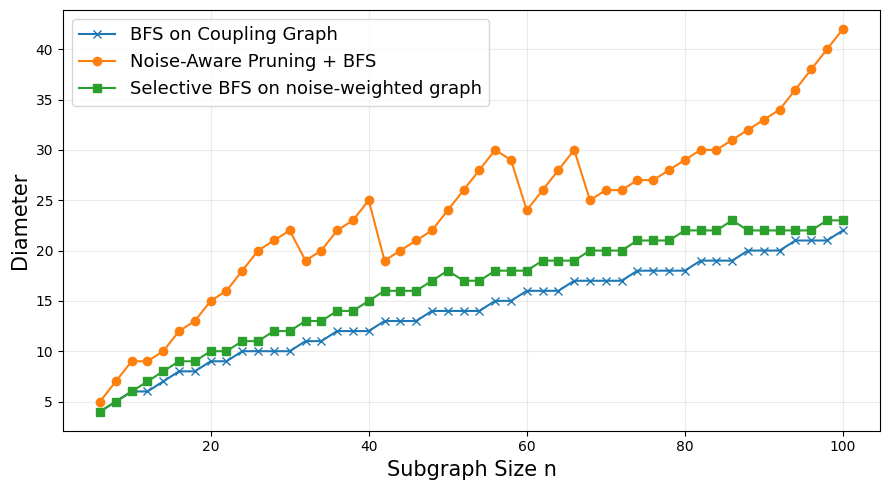

In [25]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm

# Ensure the helper functions you defined earlier are imported:
# - extract_low_noise_subgraph
# - get_coupling_graph
# - build_tree_cluster
# - central_node

def compute_diameters(backend, 
                      n_vals=range(6, 101, 2),
                      k=1,
                     ):
    diameters_nag = []
    diameters_pruned = []
    diameters_full = []

    for n in tqdm(n_vals, desc="Computing diameters"):
        try:
            H_nag = get_coupling_graph(backend)
            if H_nag is None or len(H_nag) < n:
                diameters_nag.append(float('nan'))
            else:
                root = central_node(H_nag)
                S_nag = build_tree_cluster(H_nag, source=root, n=n)
                diameter_nag = nx.diameter(S_nag)
                diameters_nag.append(diameter_nag)
        except Exception:
            diameters_nag.append(float('nan'))
        # -------------------------------
        # Method A: Noise-aware extraction first
        # -------------------------------
        try:
            H_na = extract_low_noise_subgraph(backend, n_target=int(k*n))
            if H_na is None or len(H_na) < n:
                diameters_pruned.append(float('nan'))
            else:
                root = central_node(H_na)
                S_na = build_tree_cluster(H_na, source=root, n=n)
                diameter_na = nx.diameter(S_na)
                diameters_pruned.append(diameter_na)
        except Exception:
            diameters_pruned.append(float('nan'))

        # -------------------------------
        # Method B: No pruning — weighted backend graph
        # -------------------------------
        try:
            H = get_coupling_graph(backend, weighted=True)
            high_degree_nodes = [u for u in H.nodes if H.degree(u) >= 3]
            root = max(high_degree_nodes, key=lambda q: H.nodes[q]["weight"])
            # root = central_node(H)
            S_full = selective_bfs(H, source=root, n=n)
            diameter_full = nx.diameter(S_full)
            diameters_full.append(diameter_full)
        except Exception:
            diameters_full.append(float('nan'))

    return np.array(n_vals), np.array(diameters_pruned), np.array(diameters_full), np.array(diameters_nag)


# ---- RUN EXPERIMENT ----
backend = FakeBrisbane()  # change to your backend

n_vals, dia_pruned, dia_full, dia_nag = compute_diameters(backend, k=1)

# ---- PLOT RESULTS ----
plt.figure(figsize=(9,5))
plt.plot(n_vals, dia_nag, marker='x', label="BFS on Coupling Graph")
plt.plot(n_vals, dia_pruned, marker='o', label="Noise-Aware Pruning + BFS")
plt.plot(n_vals, dia_full, marker='s', label="Selective BFS on noise-weighted graph")
plt.xlabel("Subgraph Size n", fontsize=15)
plt.ylabel("Diameter", fontsize=15)
# plt.title("Diameter of Extracted Hardware Subgraphs", fontsize=17)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=13)
plt.tight_layout()
plt.show()